# 3.4 Spatial autocorrelation of child population density (H-a, demand side)

H-a asks whether demand for childcare is spatially clustered: do subzones with many young children
sit next to other such subzones? This notebook runs global and local Moran's I on
`child_density_0_6_km2` (children aged 0-6 per km2, from `output/subzone_stats.csv`) for the 159
HDB subzones, with the same method as 3.1: a symmetric 4-nearest-neighbour graph on subzone
centroids (EPSG:3414, metres), row-standardised, 999 permutations, seed 4015. The code is Kenneth's
`scripts/spatial_autocorrelation_child_population.py`, which mirrors Daryl's fee script; the shared
statistics (`knn_weights`, `moran_i`, `permutation_inference`, `benjamini_hochberg`, the scatter and
permutation plots) are imported from `src/bt4015/moran.py`, and the GeoDataFrame-based map helpers
stay here.

**Inputs**
- `output/subzone_stats.csv` (stage 1, `build_subzone_stats`): per-subzone children 0-6 and density.
- `data/MasterPlanSubZones_2019.geojson` (subzone polygons).

**Outputs** (`output/spatial_autocorrelation_child_population/`)
- `subzone_child_moran.csv` (159 subzones with z, lag, local I, p, q and cluster labels), `global_moran_permutations.csv`, `analysis_summary.md`.
- `child_density_choropleth.png`, `global_moran_cluster_map.png`, `global_moran_scatterplot.png`, `global_moran_permutation.png`, `local_moran_lisa_map.png`, `global_moran_clusters_lisa_side_by_side.png`, `spatial_autocorrelation_overview.png`.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src" / "bt4015").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from bt4015.paths import DATA, OUT, FIG, LARGE

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import PatchCollection
from matplotlib.patches import Patch, Polygon as MplPolygon

from bt4015.moran import (CLUSTER_COLORS, benjamini_hochberg, draw_moran_scatter, draw_permutation, knn_weights,
                          lisa_quadrants, permutation_inference, set_map_style)

OUT_DIR = OUT / "spatial_autocorrelation_child_population"
OUT_DIR.mkdir(parents=True, exist_ok=True)
VARIABLE = "child_density_0_6_km2"
VAR_LABEL = "Children aged 0-6 per km\u00b2"
K = 4                 # nearest neighbours
PERMUTATIONS = 999
SEED = 4015

## 1. Load the HDB subzones and their centroids

Only subzones with HDB blocks (`has_hdb`) are analysed, because the demand estimate is built from
HDB blocks and a private-estate subzone would read as zero demand. Centroids come from the 2019
subzone polygons projected to EPSG:3414, so the KNN distances are in metres.

In [2]:
# 1. Subzone statistics restricted to HDB subzones with a density value.
stats = pd.read_csv(OUT / "subzone_stats.csv")
area_df = stats[stats["has_hdb"] == True].copy()
area_df["SUBZONE_N"] = area_df["SUBZONE_N"].str.strip().str.upper()
area_df = area_df.dropna(subset=[VARIABLE]).reset_index(drop=True)
print(f"{len(area_df)} HDB subzones with {VARIABLE}; median {area_df[VARIABLE].median():,.0f}, "
      f"max {area_df[VARIABLE].max():,.0f} children 0-6 per km2")

# 2. Polygons in metres; centroid per subzone for the weights.
gdf = gpd.read_file(DATA / "MasterPlanSubZones_2019.geojson").to_crs(epsg=3414)
gdf["SUBZONE_N"] = gdf["SUBZONE_N"].str.strip().str.upper()
centroids = gdf.copy()
centroids["cx"] = gdf.geometry.centroid.x
centroids["cy"] = gdf.geometry.centroid.y
area_df = area_df.merge(centroids[["SUBZONE_N", "cx", "cy"]], on="SUBZONE_N", how="left")
missing_geom = area_df["cx"].isna().sum()
if missing_geom:
    print(f"WARNING: {missing_geom} subzones have no matching geometry - dropped")
    area_df = area_df.dropna(subset=["cx", "cy"]).reset_index(drop=True)
print(f"subzone polygons: {len(gdf)}; analysed: {len(area_df)}")

159 HDB subzones with child_density_0_6_km2; median 746, max 3,371 children 0-6 per km2


subzone polygons: 332; analysed: 159


## 2. Weights and Moran statistics

KNN-4 on metre centroids (`lonlat=False`), symmetrised and row-standardised. The density is
standardised with the population SD, the lag is the mean of the neighbours' z, and the permutation
inference is the same conditional-randomisation routine as 3.1.

In [3]:
# 1. Symmetric KNN graph on EPSG:3414 centroids (no lon/lat correction needed).
xy = area_df[["cx", "cy"]].to_numpy(float)
binary, weights = knn_weights(xy, K, lonlat=False)
print(f"k = {K}: neighbours per subzone after symmetrising: min {int(binary.sum(1).min())}, "
      f"max {int(binary.sum(1).max())}")

# 2. Standardise, lag, permutation inference.
vals = area_df[VARIABLE].to_numpy(float)
z = (vals - vals.mean()) / vals.std(ddof=0)
lag = weights @ z
observed_i, global_p, global_perm, local_i, local_p = permutation_inference(z, weights, PERMUTATIONS, SEED)
expected_i = -1.0 / (len(z) - 1)
local_q = benjamini_hochberg(local_p)
print(f"global Moran's I = {observed_i:.4f} (expected {expected_i:.4f}), pseudo-p = {global_p:.4f}")

# 3. Cluster labels with and without the significance filter.
raw_clusters = lisa_quadrants(z, lag)
area_df["standardised_density"] = z
area_df["spatial_lag"] = lag
area_df["local_moran_i"] = local_i
area_df["local_permutation_p"] = local_p
area_df["local_fdr_q"] = local_q
area_df["lisa_quadrant"] = raw_clusters
area_df["lisa_cluster_p05"] = np.where(local_p < 0.05, raw_clusters, "Not significant")
area_df["lisa_cluster_fdr05"] = np.where(local_q < 0.05, raw_clusters, "Not significant")
area_df["neighbour_count"] = binary.sum(axis=1).astype(int)
print("local clusters at p < 0.05:", area_df["lisa_cluster_p05"].value_counts().to_dict())
print("local clusters at FDR q < 0.05:", area_df["lisa_cluster_fdr05"].value_counts().to_dict())

out_cols = ["SUBZONE_N", "PLN_AREA_N", VARIABLE, "standardised_density", "spatial_lag", "local_moran_i",
            "local_permutation_p", "local_fdr_q", "lisa_quadrant", "lisa_cluster_p05", "lisa_cluster_fdr05", "neighbour_count"]
area_df[out_cols].to_csv(OUT_DIR / "subzone_child_moran.csv", index=False)
pd.DataFrame({"permutation": np.arange(1, PERMUTATIONS + 1), "moran_i": global_perm}).to_csv(
    OUT_DIR / "global_moran_permutations.csv", index=False)

k = 4: neighbours per subzone after symmetrising: min 4, max 7


global Moran's I = 0.1867 (expected -0.0063), pseudo-p = 0.0010
local clusters at p < 0.05: {'Not significant': 130, 'Low-Low': 11, 'High-High': 10, 'Low-High': 7, 'High-Low': 1}
local clusters at FDR q < 0.05: {'Not significant': 159}


## 3. Maps

Kenneth's map helpers take a GeoDataFrame rather than Daryl's GeoJSON dicts, so they are defined
here. Colours follow the project palette: single-hue blues for the density, the LISA set for clusters.

In [4]:
def feature_patches_gdf(gdf, value_lookup, missing=np.nan):
    """Return (list[MplPolygon], np.ndarray) from a GeoDataFrame + value lookup keyed by SUBZONE_N."""
    patches, values = [], []
    for _, row in gdf.iterrows():
        val = value_lookup.get(row["SUBZONE_N"], missing)
        geom = row.geometry
        polys = list(geom.geoms) if geom.geom_type == "MultiPolygon" else [geom]
        for poly in polys:
            patches.append(MplPolygon(np.array(poly.exterior.coords), closed=True))
            values.append(val)
    return patches, np.asarray(values)


def add_pa_boundaries(ax, gdf_all):
    """Overlay dissolved planning-area outlines as faint geographic reference."""
    gdf_all.dissolve(by="PLN_AREA_N").boundary.plot(ax=ax, color="#f5f5f5", linewidth=0.6, zorder=3)


def draw_density_map(ax, gdf, area_df):
    """Choropleth of children 0-6 per km2 (subzones without HDB in grey)."""
    lookup = dict(zip(area_df["SUBZONE_N"], area_df[VARIABLE]))
    patches, values = feature_patches_gdf(gdf, lookup)
    cmap = plt.cm.Blues.copy()   # changed 2026-11-10: single-hue blues instead of YlOrRd (project palette)
    cmap.set_bad("#e0e0e0")
    coll = PatchCollection(patches, cmap=cmap, edgecolor="none", linewidth=0)
    coll.set_antialiased(False)
    coll.set_array(np.ma.masked_invalid(values))
    ax.add_collection(coll)
    add_pa_boundaries(ax, gdf)
    ax.autoscale_view()
    set_map_style(ax)
    ax.set_title("Child Population Density by Subzone\n(ages 0-6, per km\u00b2)", fontweight="bold")
    cbar = ax.figure.colorbar(coll, ax=ax, fraction=0.032, pad=0.01)
    cbar.set_label(VAR_LABEL)
    return coll


def draw_cluster_map(ax, gdf, area_df, column, title, order):
    """Categorical map of Moran quadrants (`lisa_quadrant`) or significant clusters (`lisa_cluster_p05`)."""
    lookup = dict(zip(area_df["SUBZONE_N"], area_df[column]))
    patches, clusters = feature_patches_gdf(gdf, lookup, missing="No data")
    colors = [CLUSTER_COLORS[str(c)] for c in clusters]
    coll = PatchCollection(patches, facecolor=colors, edgecolor="none", linewidth=0)
    coll.set_antialiased(False)
    ax.add_collection(coll)
    add_pa_boundaries(ax, gdf)
    ax.autoscale_view()
    set_map_style(ax)
    ax.set_title(title, fontweight="bold")
    counts = area_df[column].value_counts().to_dict()
    ax.legend(handles=[Patch(facecolor=CLUSTER_COLORS[c], label=f"{c} ({counts.get(c, 0)})") for c in order],
              loc="lower left", frameon=True, fontsize=8)


def draw_global_moran_cluster_map(ax, gdf, area_df):
    draw_cluster_map(ax, gdf, area_df, "lisa_quadrant", "Global Moran Clusters by Subzone\n(child density 0-6)",
                     ["High-High", "Low-Low", "High-Low", "Low-High"])


def draw_lisa_map(ax, gdf, area_df):
    draw_cluster_map(ax, gdf, area_df, "lisa_cluster_p05", "Local Moran (LISA) Clusters by Subzone\n(child density 0-6)",
                     ["High-High", "Low-Low", "High-Low", "Low-High", "Not significant"])


def show_plot(draw_fn, path, figsize=(9, 7)):
    """Draw one figure, save it and show it inline."""
    fig, ax = plt.subplots(figsize=figsize)
    draw_fn(ax)
    fig.tight_layout()
    fig.savefig(path, dpi=220, bbox_inches="tight")
    plt.show()


names = area_df["SUBZONE_N"].to_numpy()

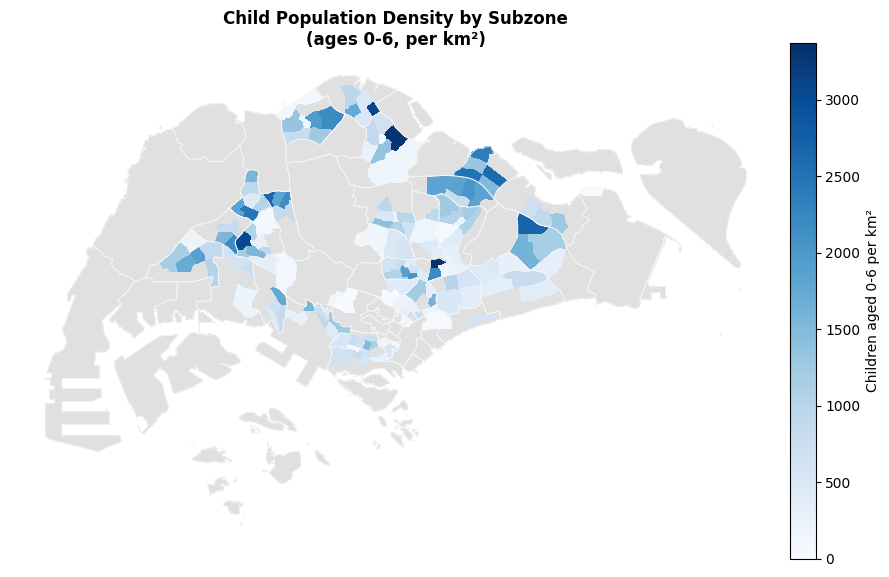

In [5]:
show_plot(lambda ax: draw_density_map(ax, gdf, area_df), OUT_DIR / "child_density_choropleth.png")

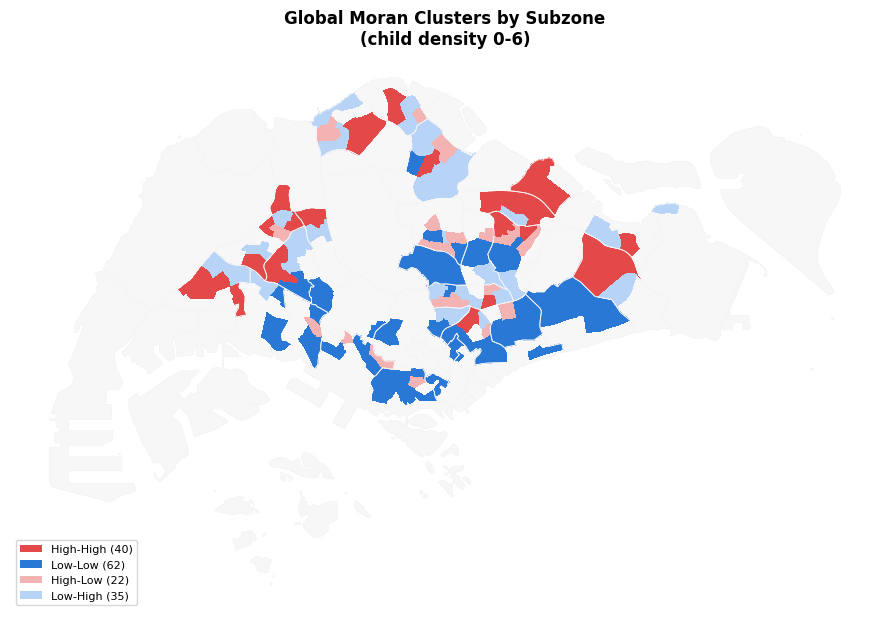

In [6]:
show_plot(lambda ax: draw_global_moran_cluster_map(ax, gdf, area_df), OUT_DIR / "global_moran_cluster_map.png")

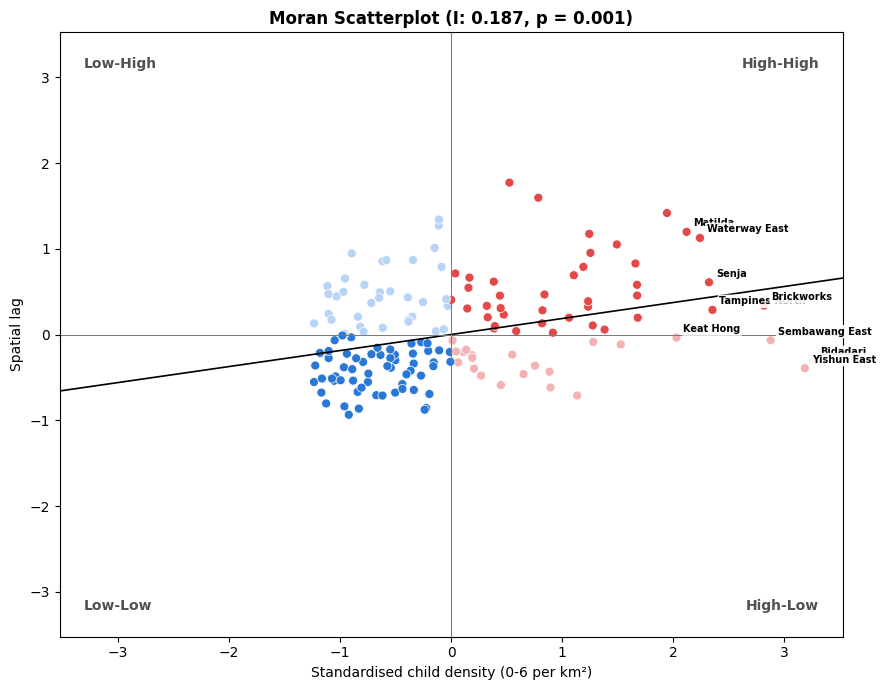

In [7]:
show_plot(lambda ax: draw_moran_scatter(ax, z, lag, observed_i, global_p, names, annotate_names=False,
                                        xlabel="Standardised child density (0-6 per km\u00b2)", annotate_outliers=True),
          OUT_DIR / "global_moran_scatterplot.png")

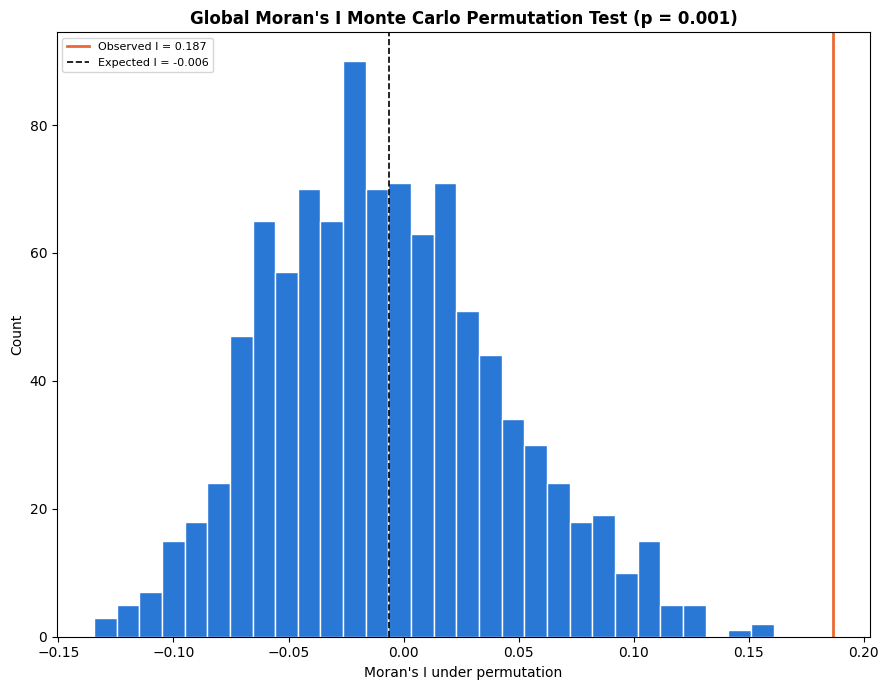

In [8]:
show_plot(lambda ax: draw_permutation(ax, global_perm, observed_i, expected_i, global_p),
          OUT_DIR / "global_moran_permutation.png")

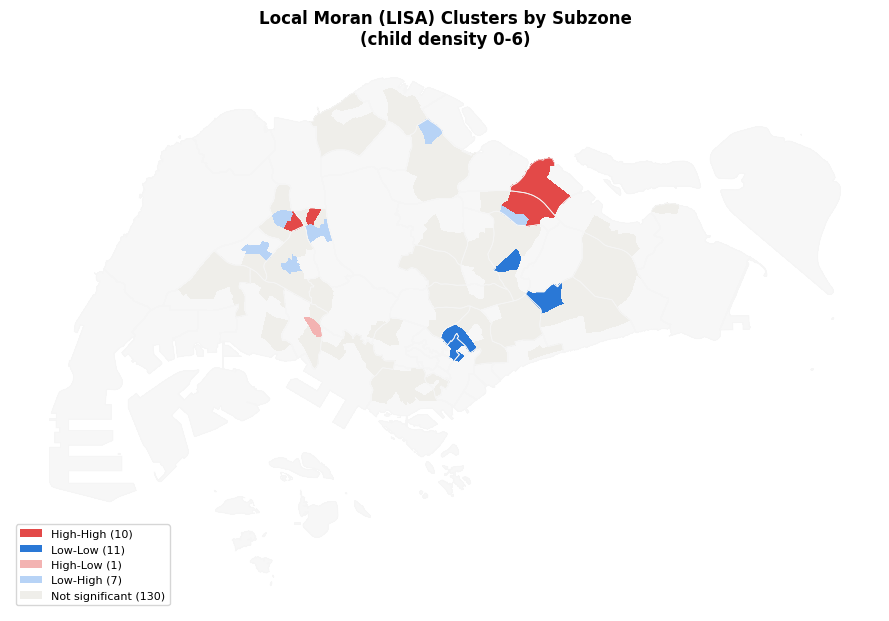

In [9]:
show_plot(lambda ax: draw_lisa_map(ax, gdf, area_df), OUT_DIR / "local_moran_lisa_map.png")

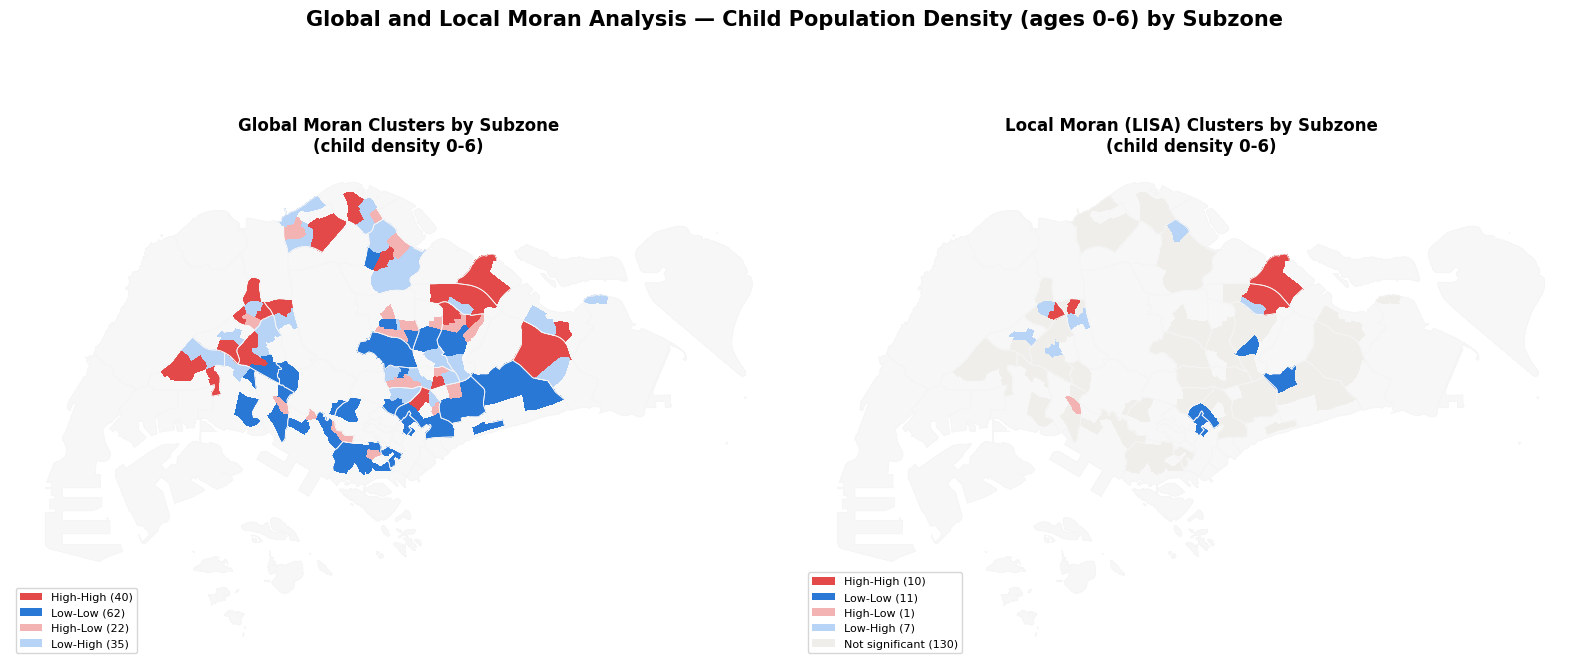

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
draw_global_moran_cluster_map(axes[0], gdf, area_df)
draw_lisa_map(axes[1], gdf, area_df)
fig.suptitle("Global and Local Moran Analysis — Child Population Density (ages 0-6) by Subzone", fontsize=15, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(OUT_DIR / "global_moran_clusters_lisa_side_by_side.png", dpi=220, bbox_inches="tight")
plt.show()

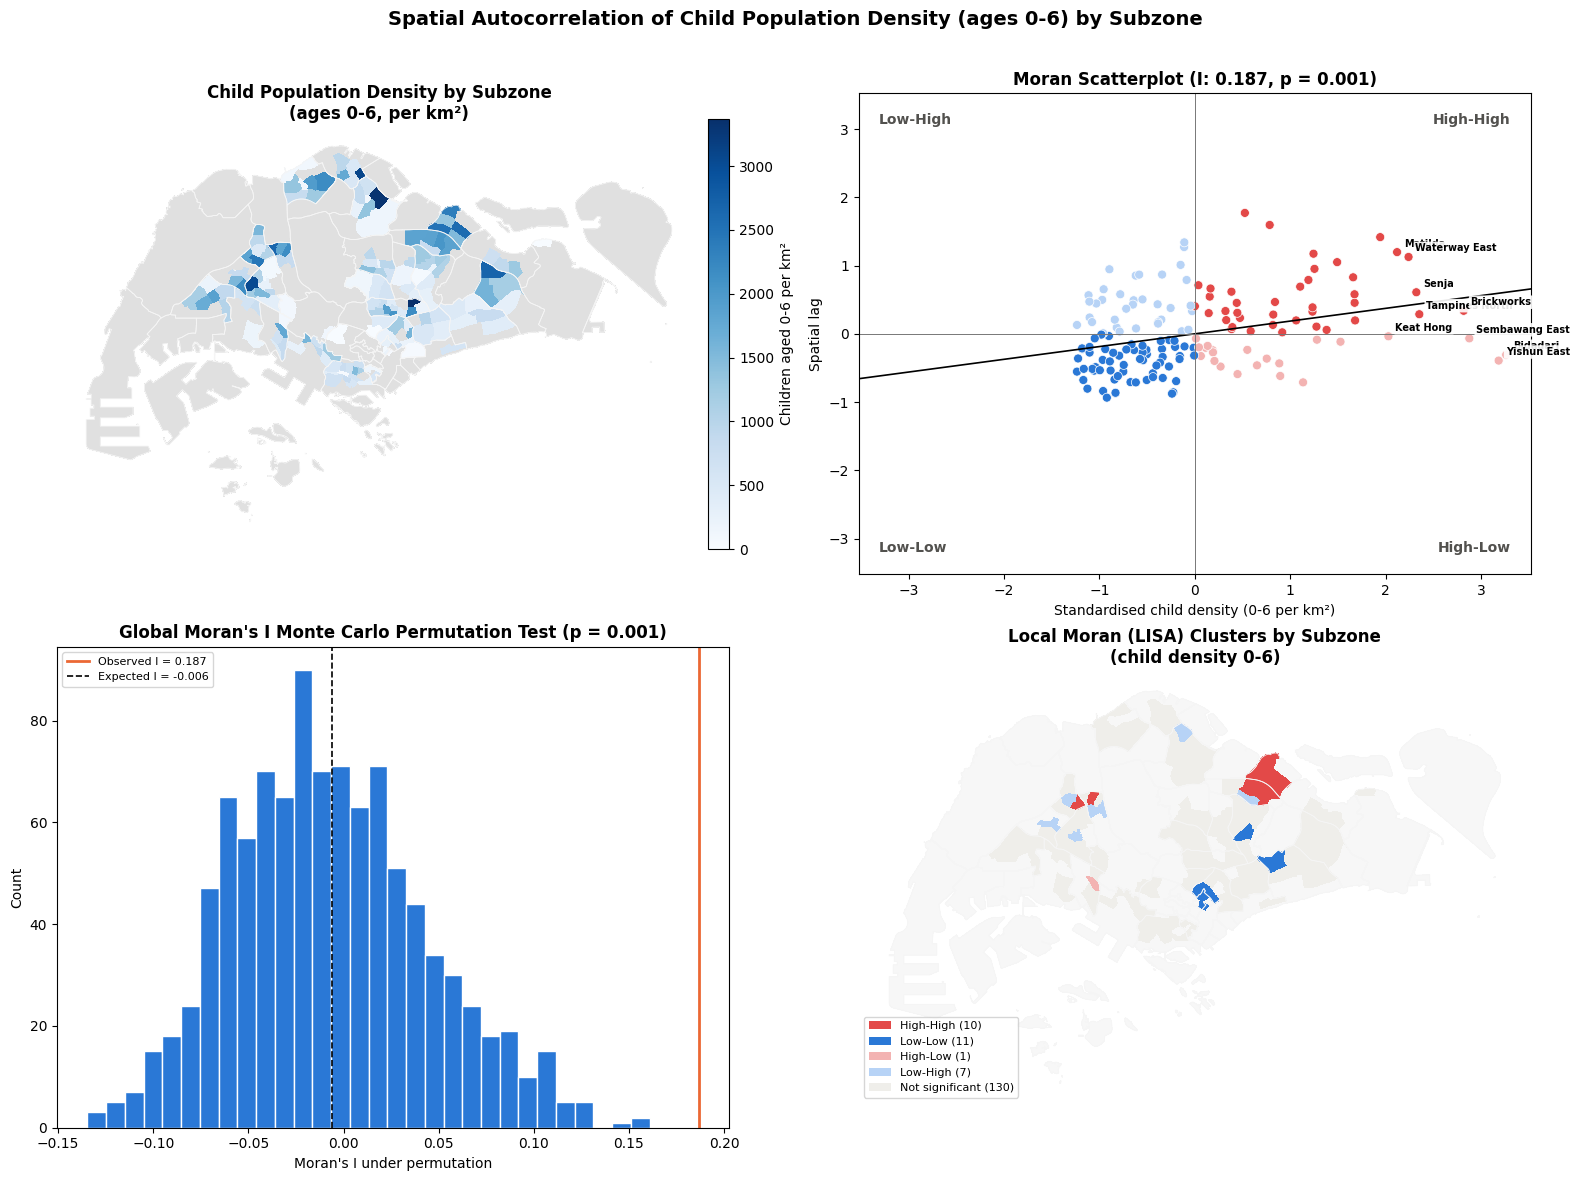

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
draw_density_map(axes[0, 0], gdf, area_df)
draw_moran_scatter(axes[0, 1], z, lag, observed_i, global_p, names, annotate_names=False,
                   xlabel="Standardised child density (0-6 per km\u00b2)", annotate_outliers=True)
draw_permutation(axes[1, 0], global_perm, observed_i, expected_i, global_p)
draw_lisa_map(axes[1, 1], gdf, area_df)
fig.suptitle("Spatial Autocorrelation of Child Population Density (ages 0-6) by Subzone", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(OUT_DIR / "spatial_autocorrelation_overview.png", dpi=220, bbox_inches="tight")
plt.show()

## 4. Summary

Positive, significant clustering: the high-high cluster is the Punggol-Sengkang new-town belt, where
the youngest estates sit next to each other. This is the demand-side half of the story; 3.7 shows
whether supply keeps up there.

**Why KNN here and Queen contiguity in 3.7.** Kenneth kept Daryl's KNN-4 graph so the fee and
demand surfaces are tested with identical weights and the two Moran's I values are comparable. The
pressure-index LISA in 3.7 uses Queen contiguity (islands attached to their nearest neighbour,
`src/bt4015/spatial_weights.py`) because the pressure index is a catchment measure: a subzone's
pressure is shared with the subzones it physically borders, not with the four nearest centroids,
which for the large western subzones can be many kilometres away. Both are reported so the reader
can see that the clustering verdicts do not depend on the weights choice (3.7 also reports Rook
contiguity).

In [12]:
direction = "positive" if observed_i > expected_i else "negative"
decision = "statistically significant" if global_p < 0.05 else "not statistically significant"
sig = area_df.loc[area_df["local_permutation_p"] < 0.05,
                  ["SUBZONE_N", "PLN_AREA_N", VARIABLE, "lisa_cluster_p05", "local_moran_i", "local_permutation_p", "local_fdr_q"]
                  ].sort_values(["lisa_cluster_p05", "local_permutation_p"])
summary = f"""# Spatial autocorrelation of child population density (ages 0-6) by subzone

## Method

- Variable: `{VARIABLE}` (children aged 0-6 per km2, from subzone_stats.csv)
- child_0_6 = child_0_4 + per-subzone share_5_6 * child_5_9 (fallback: flat 40%).
- Spatial unit: 2019 subzones restricted to {len(area_df)} HDB subzones (has_hdb == True).
- Spatial weights: symmetric {K}-nearest-neighbour graph on EPSG:3414 centroids, row-standardised.
- Inference: {PERMUTATIONS:,} random permutations, seed {SEED}.
  Local p-values use conditional randomisation; Benjamini-Hochberg FDR q-values also reported.

## Global Moran's I

- Observed I: **{observed_i:.4f}**
- Expected I (under randomisation): **{expected_i:.4f}**
- Permutation pseudo-p: **{global_p:.4f}**

Child density (ages 0-6) shows **{direction} spatial autocorrelation** across HDB subzones,
and the result is **{decision} at the 5% level**.

## Local Moran clusters (raw permutation p < 0.05)

{sig.to_string(index=False) if len(sig) else "No subzone is locally significant at raw p < 0.05."}

Note: local results involve multiple comparisons. Slides use raw pseudo-p < 0.05 (`lisa_cluster_p05`); report uses FDR q < 0.05 (`lisa_cluster_fdr05`)
for confirmatory inference.
"""
(OUT_DIR / "analysis_summary.md").write_text(summary, encoding="utf-8")
print(summary)
print(f"written to {OUT_DIR.relative_to(ROOT)}/: subzone_child_moran.csv ({len(area_df)} rows), "
      f"global_moran_permutations.csv ({PERMUTATIONS} rows), analysis_summary.md and 7 PNGs")

# Spatial autocorrelation of child population density (ages 0-6) by subzone

## Method

- Variable: `child_density_0_6_km2` (children aged 0-6 per km2, from subzone_stats.csv)
- child_0_6 = child_0_4 + per-subzone share_5_6 * child_5_9 (fallback: flat 40%).
- Spatial unit: 2019 subzones restricted to 159 HDB subzones (has_hdb == True).
- Spatial weights: symmetric 4-nearest-neighbour graph on EPSG:3414 centroids, row-standardised.
- Inference: 999 random permutations, seed 4015.
  Local p-values use conditional randomisation; Benjamini-Hochberg FDR q-values also reported.

## Global Moran's I

- Observed I: **0.1867**
- Expected I (under randomisation): **-0.0063**
- Permutation pseudo-p: **0.0010**

Child density (ages 0-6) shows **positive spatial autocorrelation** across HDB subzones,
and the result is **statistically significant at the 5% level**.

## Local Moran clusters (raw permutation p < 0.05)

            SUBZONE_N    PLN_AREA_N  child_density_0_6_km2 lisa_cluster_p05  local_